# 50 Pandas + NumPy Integration Practice Questions
> **Instructions:** Each question requires both **Pandas** and **NumPy**. Focus on interoperability, vectorized operations, and building ML-ready datasets.  
> **Do NOT look at solutions** — hints are provided to guide your thinking.  
> Recommended pace: 5–10 questions per day

---

## NP1–NP10: Array Conversions & Basic Integration

---

In [24]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Name': ['Rahul', 'Ganraj', 'Neha', 'Priya'],
    'Marks': [95, 70, 88, 70],
    'City': ['Pune', 'Mumbai', 'Delhi', 'Nashik']
})

print(df)

     Name  Marks    City
0   Rahul     95    Pune
1  Ganraj     70  Mumbai
2    Neha     88   Delhi
3   Priya     70  Nashik


### NP1. Create a NumPy array and convert it to a Pandas Series.
> 💡 **Hint:** `np.array([...])` creates the array. Pass it directly to `pd.Series(array, index=[...], name="...")`.

---

In [26]:
# To find the relationship between NumPy (computation)
# and Pandas (labeling/analysis).

arr = np.array(df["Marks"])

marks_series = pd.Series(
    arr,
    index=df["Name"],
    name="Student_Marks"
)

print(marks_series)

Name
Rahul     95
Ganraj    70
Neha      88
Priya     70
Name: Student_Marks, dtype: int64


### NP2. Convert a 2D NumPy array to a Pandas DataFrame.
> 💡 **Hint:** `pd.DataFrame(np_2d_array, columns=[...])` — shape `(n, m)` gives `n` rows and `m` columns.

---

In [28]:
# 2D NumPy Array -> DataFrame
arr_2d = df[["Marks"]].values

new_df = pd.DataFrame(
    arr_2d,
    columns=["Marks"]
)

print(new_df)

   Marks
0     95
1     70
2     88
3     70


### NP3. Generate a random dataset using NumPy and store it in a DataFrame.
> 💡 **Hint:** Use `np.random.seed()` for reproducibility. Try `np.random.randn(n, m)` for normal distribution or `np.random.randint(lo, hi, n)` for integers.

---

In [30]:
# Always use seed() for reproducible results.
np.random.seed(42)

random_scores = np.random.randint(
    60,
    100,
    size=(4, 2)
)

random_df = pd.DataFrame(
    random_scores,
    columns=["Maths", "Science"]
)

print(random_df)

   Maths  Science
0     98       88
1     74       67
2     80       98
3     78       82


### NP4. Perform element-wise operations using NumPy and Pandas.
> 💡 **Hint:** You can apply NumPy ufuncs directly on a Pandas Series: `np.sqrt(df["col"])`. The result is a Series.

---

In [32]:
# NumPy ufuncs work directly on Pandas columns.
df["Sqrt_Marks"] = np.sqrt(df["Marks"])
df["Sqrt_Marks"]

0    9.746794
1    8.366600
2    9.380832
3    8.366600
Name: Sqrt_Marks, dtype: float64

In [33]:
df["Updated_Marks"] = df["Marks"] + 5

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks
0   Rahul     95    Pune    9.746794            100
1  Ganraj     70  Mumbai    8.366600             75
2    Neha     88   Delhi    9.380832             93
3   Priya     70  Nashik    8.366600             75


### NP5. Apply `np.mean` on DataFrame columns.
> 💡 **Hint:** `np.mean(df["col"])` works the same as `df["col"].mean()`. Apply to the `.values` array for pure NumPy speed: `np.mean(df["col"].values)`.

---

In [36]:
# np.mean() and .mean() produce the same result.
avg_marks = np.mean(df["Marks"])
avg_marks

np.float64(80.75)

In [35]:
# Pure NumPy approach
avg_marks = np.mean(df["Marks"].values)
avg_marks

np.float64(80.75)

### NP6. Replace values using `np.where`.
> 💡 **Hint:** `np.where(condition, value_if_true, value_if_false)` — assign the result back to a column: `df["col"] = np.where(df["col"] > 50, "High", "Low")`.

---

In [39]:
# np.where() is the fastest way to create conditional columns.
df["Performance"] = np.where(
    df["Marks"] >= 80,
    "Pass",
    "Needs Improvement"
)

df["Performance"]

0                 Pass
1    Needs Improvement
2                 Pass
3    Needs Improvement
Name: Performance, dtype: object

### NP7. Apply logarithmic transformation using `np.log`.
> 💡 **Hint:** `df["col_log"] = np.log(df["col"])`. Note: `np.log(0)` returns `-inf`. Use `np.log1p(x)` which computes `log(1 + x)` to safely handle zeros.

---

In [41]:
# Use log transformation for highly skewed numeric data.
df["Log_Marks"] = np.log(df["Marks"])

print(df[["Marks", "Log_Marks"]])

   Marks  Log_Marks
0     95   4.553877
1     70   4.248495
2     88   4.477337
3     70   4.248495


### NP8. Apply square root transformation using `np.sqrt`.
> 💡 **Hint:** `df["col_sqrt"] = np.sqrt(df["col"])`. Values must be non-negative; use `np.clip(df["col"], 0, None)` first if negatives are possible.

---

In [42]:
df["Sqrt_Marks"] = np.sqrt(df["Marks"])

print(df[["Marks", "Sqrt_Marks"]])

   Marks  Sqrt_Marks
0     95    9.746794
1     70    8.366600
2     88    9.380832
3     70    8.366600


### NP9. Use NumPy functions inside `apply()`.
> 💡 **Hint:** `df["col"].apply(lambda x: np.log(x))` — or pass the NumPy function directly: `df["col"].apply(np.log)`.

---

In [44]:
# By using np.log()
df["Log_Marks"] = np.log(df["Marks"])
df["Log_Marks"]

0    4.553877
1    4.248495
2    4.477337
3    4.248495
Name: Log_Marks, dtype: float64

In [45]:
# By using df["col"].apply()
df["Log_Marks"] = df["Marks"].apply(np.log)

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  
0   4.553877  
1   4.248495  
2   4.477337  
3   4.248495  


### NP10. Perform broadcasting in a DataFrame using NumPy.
> 💡 **Hint:** Extract `.values` (a 2D NumPy array) and multiply by a weights array: `df[cols].values @ weights_array`. The result can be assigned back as a new column.

In [46]:
# Since we only have one numeric column (Marks), 
# let's scale marks by 10%

bonus_factor = np.array([1.10])

df["Bonus_Marks"] = (
    df[["Marks"]].values * bonus_factor
)

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  
0   4.553877        104.5  
1   4.248495         77.0  
2   4.477337         96.8  
3   4.248495         77.0  


## NP11–NP20: Data Filtering, Transformation & Statistics

---

### NP11. Filter DataFrame rows using a NumPy boolean mask.
> 💡 **Hint:** `mask = np.array(df["col"]) > threshold` creates a NumPy boolean array. Use `df[mask]` to filter.

---

In [48]:
# Boolean indexing -> core data filtering
mask = np.array(df["Marks"]) > 80

filtered_df = df[mask]

print(filtered_df)

    Name  Marks   City  Sqrt_Marks  Updated_Marks Performance  Log_Marks  \
0  Rahul     95   Pune    9.746794            100        Pass   4.553877   
2   Neha     88  Delhi    9.380832             93        Pass   4.477337   

   Bonus_Marks  
0        104.5  
2         96.8  


### NP12. Count non-zero values in a column using NumPy.
> 💡 **Hint:** `np.count_nonzero(df["col"].values)` or `np.count_nonzero(df["col"].values != 0)`.

---

In [49]:
count = np.count_nonzero(df["Marks"].values)

print(count)

4


### NP13. Find unique values using `np.unique`.
> 💡 **Hint:** `np.unique(df["col"])` returns sorted unique values. Use `return_counts=True` to also get the frequency of each unique value.

---

In [52]:
# np.unique() automatically sorts the output.
cities = np.unique(df["City"])

print(cities)

['Delhi' 'Mumbai' 'Nashik' 'Pune']


In [51]:
# If you want frequency also, then
unique_vals, counts = np.unique(
    df["Marks"],
    return_counts=True
)

print(unique_vals)
print(counts)

[70 88 95]
[2 1 1]


### NP14. Flatten DataFrame values to a 1D NumPy array.
> 💡 **Hint:** `df[["col1","col2"]].values.flatten()` — the `.flatten()` method converts the 2D array to 1D row-by-row.

> Flattening converts rows and columns into one continuous sequence.
---

In [53]:
# For a single column
flat = df[["Marks"]].values.flatten()

print(flat)

[95 70 88 70]


In [54]:
# For a multiple columns
flat = df[["Name", "Marks"]].values.flatten()
flat

array(['Rahul', 95, 'Ganraj', 70, 'Neha', 88, 'Priya', 70], dtype=object)

### NP15. Reshape a NumPy array before creating a DataFrame.
> 💡 **Hint:** `np.arange(1, 25).reshape(6, 4)` creates a 6×4 array. Pass directly to `pd.DataFrame(arr, columns=[...])`.

> Rows × Columns must equal total elements.
---

In [55]:
arr = np.arange(1, 13).reshape(4, 3)

new_df = pd.DataFrame(
    arr,
    columns=["A", "B", "C"]
)

print(new_df)

    A   B   C
0   1   2   3
1   4   5   6
2   7   8   9
3  10  11  12


### NP16. Perform matrix multiplication using `np.dot`.
> 💡 **Hint:** `np.dot(A, B)` or `A @ B`. Extract `.values` from DataFrames first, then wrap the result in a new `pd.DataFrame(result, columns=[...])`.

---

In [56]:
# Multiply marks by weight
A = df[["Marks"]].values

weights = np.array([[0.1]])

result = np.dot(A, weights)

print(result)

[[9.5]
 [7. ]
 [8.8]
 [7. ]]


In [57]:
# @ is simply cleaner syntax for matrix multiplication.
A @ weights

array([[9.5],
       [7. ],
       [8.8],
       [7. ]])

### NP17. Normalize data using NumPy (Min-Max scaling).
> 💡 **Hint:** `arr = df[cols].values` then `(arr - arr.min(axis=0)) / (arr.max(axis=0) - arr.min(axis=0))`. Use `axis=0` to operate column-wise.

> 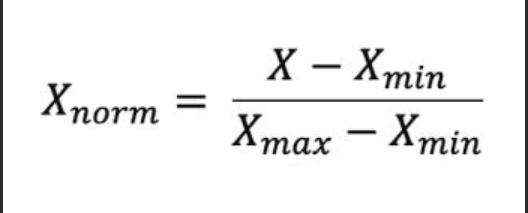
---

In [58]:
arr = df[["Marks"]].values

normalized = (
    arr - arr.min(axis=0)
) / (
    arr.max(axis=0) - arr.min(axis=0)
)

df["Marks_Normalized"] = normalized

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized  
0   4.553877        104.5              1.00  
1   4.248495         77.0              0.00  
2   4.477337         96.8              0.72  
3   4.248495         77.0              0.00  


### NP18. Standardize data using Z-score with NumPy.
> 💡 **Hint:** `z = (arr - arr.mean(axis=0)) / arr.std(axis=0)`. Wrap the result in a DataFrame using the original column names.

> Standardization centers data around 0 with standard deviation 1.

> 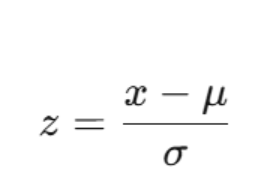
---

In [59]:
arr = df["Marks"].values

z_scores = (
    arr - arr.mean()
) / arr.std()

df["Z_Score"] = z_scores

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  
0   4.553877        104.5              1.00  1.291790  
1   4.248495         77.0              0.00 -0.974508  
2   4.477337         96.8              0.72  0.657226  
3   4.248495         77.0              0.00 -0.974508  


### NP19. Clip values using `np.clip`.
> 💡 **Hint:** `np.clip(df["col"].values, a_min=lower_bound, a_max=upper_bound)` — values outside the range are replaced by the boundary values.

> Clipping creates hard boundaries.
---

In [61]:
# marks must remain between 75 and 90.
clipped = np.clip(
    df["Marks"],
    a_min=75,
    a_max=90
)

print(clipped)

0    90
1    75
2    88
3    75
Name: Marks, dtype: int64


### NP20. Handle missing values using NumPy.
> 💡 **Hint:** Detect NaN with `np.isnan(arr)`. Fill using `np.nanmean(arr)` to compute the mean ignoring NaN, then replace: `arr[np.isnan(arr)] = np.nanmean(arr)`.

> np.nanmean() ignores NaN while computing averages.
---

In [62]:
# Create missing value
df_nan = df.copy()

df_nan.loc[1, "Marks"] = np.nan

In [63]:
# Detect & Fill
arr = df_nan["Marks"].values

arr[np.isnan(arr)] = np.nanmean(arr)

df_nan["Marks"] = arr

print(df_nan)

     Name      Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul  95.000000    Pune    9.746794            100               Pass   
1  Ganraj  84.333333  Mumbai    8.366600             75  Needs Improvement   
2    Neha  88.000000   Delhi    9.380832             93               Pass   
3   Priya  70.000000  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  
0   4.553877        104.5              1.00  1.291790  
1   4.248495         77.0              0.00 -0.974508  
2   4.477337         96.8              0.72  0.657226  
3   4.248495         77.0              0.00 -0.974508  


In [64]:
# Filled Value:-

(95 + 88 + 70) / 3

84.33333333333333

## NP21–NP30: Performance, Sorting & Statistical Analysis

---

### NP21. Compare NumPy vs Pandas performance on a large array.
> 💡 **Hint:** Use `time.time()` before and after each operation. Apply the same computation (`arr * 2 + 1`) to a raw NumPy array and a Pandas Series. NumPy is typically faster on pure numeric operations.

---

In [66]:
import time

arr = np.random.rand(1_000_000)
s = pd.Series(arr)

start = time.time()
arr * 2 + 1
numpy_time = time.time() - start
print(numpy_time)

start = time.time()
s * 2 + 1
pandas_time = time.time() - start
print(pandas_time)

0.012038230895996094
0.012980461120605469


### NP22. Calculate cumulative sum using NumPy.
> 💡 **Hint:** `np.cumsum(df["col"].values)` — assign back: `df["cum_col"] = np.cumsum(df["col"])`.

> Cumulative sum shows running totals.
---

In [67]:
df["Cumulative_Marks"] = np.cumsum(
    df["Marks"]
)

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  
0   4.553877        104.5              1.00  1.291790                95  
1   4.248495         77.0              0.00 -0.974508               165  
2   4.477337         96.8              0.72  0.657226               253  
3   4.248495         77.0              0.00 -0.974508               323  


### NP23. Use `np.argmax` and `np.argmin`.
> 💡 **Hint:** `np.argmax(df["col"].values)` returns the **integer position** of the maximum. Use `df.iloc[idx]` or `df.loc[idx]` to retrieve the full row.

> argmax() returns position, not value.
---

In [69]:
max_idx = np.argmax(df["Marks"])
min_idx = np.argmin(df["Marks"])

print(df.iloc[max_idx])
print(df.iloc[min_idx])

Name                   Rahul
Marks                     95
City                    Pune
Sqrt_Marks          9.746794
Updated_Marks            100
Performance             Pass
Log_Marks           4.553877
Bonus_Marks            104.5
Marks_Normalized         1.0
Z_Score              1.29179
Cumulative_Marks          95
Name: 0, dtype: object
Name                           Ganraj
Marks                              70
City                           Mumbai
Sqrt_Marks                     8.3666
Updated_Marks                      75
Performance         Needs Improvement
Log_Marks                    4.248495
Bonus_Marks                      77.0
Marks_Normalized                  0.0
Z_Score                     -0.974508
Cumulative_Marks                  165
Name: 1, dtype: object


### NP24. Sort values using NumPy `np.argsort`.
> 💡 **Hint:** `sorted_idx = np.argsort(df["col"].values)` gives indices that would sort the array. Use `df.iloc[sorted_idx]` to reorder the DataFrame.

> argsort() gives the sorting order, not the sorted values.
---

In [70]:
sorted_idx = np.argsort(
    df["Marks"].values
)

sorted_df = df.iloc[sorted_idx]

print(sorted_df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
0   Rahul     95    Pune    9.746794            100               Pass   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  
1   4.248495         77.0              0.00 -0.974508               165  
3   4.248495         77.0              0.00 -0.974508               323  
2   4.477337         96.8              0.72  0.657226               253  
0   4.553877        104.5              1.00  1.291790                95  


### NP25. Compute correlation using `np.corrcoef`.
> 💡 **Hint:** `np.corrcoef([df["col1"].values, df["col2"].values])` returns a 2×2 correlation matrix. Wrap in a DataFrame for readability. Compare with `df.corr()`.

> Correlation measures direction and strength of relationship.
---

In [71]:
df["Bonus"] = [5,10,3,8]

corr = np.corrcoef(
    df["Marks"],
    df["Bonus"]
)

print(corr)

[[ 1.         -0.84589037]
 [-0.84589037  1.        ]]


### NP26. Detect NaN values using NumPy.
> 💡 **Hint:** `np.isnan(arr)` returns a boolean array. Count NaN with `np.isnan(arr).sum()`. Compare with `pd.isnull(series)`.

> isnan() is NumPy's NaN detector.
---

In [72]:
arr = np.array([95, np.nan, 88, 70])

np.isnan(arr)

array([False,  True, False, False])

In [73]:
# Count NaN
np.isnan(arr).sum()

np.int64(1)

### NP27. Create boolean masks using NumPy.
> 💡 **Hint:** `mask = (np.array(df["col1"]) > 80) & (np.array(df["col2"]) < 40)` — use `df[mask]` to filter.

---

In [74]:
mask = (
    np.array(df["Marks"]) > 80
)

filtered = df[mask]

print(filtered)

    Name  Marks   City  Sqrt_Marks  Updated_Marks Performance  Log_Marks  \
0  Rahul     95   Pune    9.746794            100        Pass   4.553877   
2   Neha     88  Delhi    9.380832             93        Pass   4.477337   

   Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  Bonus  
0        104.5              1.00  1.291790                95      5  
2         96.8              0.72  0.657226               253      3  


### NP28. Apply logical operations (`np.logical_and`, `np.logical_or`, `np.logical_not`).
> 💡 **Hint:** `np.logical_and(cond1, cond2)` is equivalent to `cond1 & cond2`. These functions work on NumPy arrays; convert Series with `.values` first.

---

In [75]:
cond1 = df["Marks"] > 80
cond2 = df["City"] == "Pune"

np.logical_and(cond1, cond2)

0     True
1    False
2    False
3    False
dtype: bool

### NP29. Apply `np.select` for multi-condition assignment.
> 💡 **Hint:** `df["Grade"] = np.select([df["Score"] >= 90, df["Score"] >= 75], ["A","B"], default="C")` — conditions are checked in order; the first match wins.

---

In [76]:
conditions = [
    df["Marks"] >= 90,
    df["Marks"] >= 75
]

choices = ["A", "B"]

df["Grade"] = np.select(
    conditions,
    choices,
    default="C"
)

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  \
0   4.553877        104.5              1.00  1.291790                95   
1   4.248495         77.0              0.00 -0.974508               165   
2   4.477337         96.8              0.72  0.657226               253   
3   4.248495         77.0              0.00 -0.974508               323   

   Bonus Grade  
0      5     A  
1     10     C  
2      3     B  
3      8     C  


### NP30. Multiply DataFrame columns element-wise using NumPy.
> 💡 **Hint:** `np.multiply(df["col1"].values, df["col2"].values)` is equivalent to `df["col1"] * df["col2"]` but uses NumPy internally.

---

In [78]:
# Since only one numeric column exists, create another:
df["Attendance"] = [90, 85, 95, 80]

In [79]:
result = np.multiply(
    df["Marks"],
    df["Attendance"]
)

df["Performance_Index"] = result

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul     95    Pune    9.746794            100               Pass   
1  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
2    Neha     88   Delhi    9.380832             93               Pass   
3   Priya     70  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  \
0   4.553877        104.5              1.00  1.291790                95   
1   4.248495         77.0              0.00 -0.974508               165   
2   4.477337         96.8              0.72  0.657226               253   
3   4.248495         77.0              0.00 -0.974508               323   

   Bonus Grade  Attendance  Performance_Index  
0      5     A          90               8550  
1     10     C          85               5950  
2      3     B          95               8360  
3      8     C          80               5600  


## NP31–NP40: Data Wrangling & Conversion

---

### NP31. Shuffle dataset rows using NumPy.
> 💡 **Hint:** `shuffled_idx = np.random.permutation(df.index)` creates a random permutation of row indices. Use `df.loc[shuffled_idx].reset_index(drop=True)`.

---

In [80]:
np.random.seed(42)

shuffled_idx = np.random.permutation(df.index)

shuffled_df = (
    df.loc[shuffled_idx]
      .reset_index(drop=True)
)

print(shuffled_df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0  Ganraj     70  Mumbai    8.366600             75  Needs Improvement   
1   Priya     70  Nashik    8.366600             75  Needs Improvement   
2   Rahul     95    Pune    9.746794            100               Pass   
3    Neha     88   Delhi    9.380832             93               Pass   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  \
0   4.248495         77.0              0.00 -0.974508               165   
1   4.248495         77.0              0.00 -0.974508               323   
2   4.553877        104.5              1.00  1.291790                95   
3   4.477337         96.8              0.72  0.657226               253   

   Bonus Grade  Attendance  Performance_Index  
0     10     C          85               5950  
1      8     C          80               5600  
2      5     A          90               8550  
3      3     B          95               8360  


### NP32. Sample random rows using NumPy.
> 💡 **Hint:** `sample_idx = np.random.choice(df.index, size=N, replace=False)` — use `df.loc[sample_idx]`. Compare with `df.sample(N)`.

> Sampling selects a subset; shuffling reorders the entire dataset.
---

In [81]:
sample_idx = np.random.choice(
    df.index,
    size=2,
    replace=False
)

sample_df = df.loc[sample_idx]

print(sample_df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
1  Ganraj     70  Mumbai      8.3666             75  Needs Improvement   
3   Priya     70  Nashik      8.3666             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  \
1   4.248495         77.0               0.0 -0.974508               165   
3   4.248495         77.0               0.0 -0.974508               323   

   Bonus Grade  Attendance  Performance_Index  
1     10     C          85               5950  
3      8     C          80               5600  


### NP33. Calculate percentiles using NumPy.
> 💡 **Hint:** `np.percentile(df["col"].values, [25, 50, 75])` returns Q1, median, Q3. Use `np.percentile(arr, p)` for any percentile p in [0, 100].

---

In [82]:
# Percentiles describe position, not spread.
np.percentile(
    df["Marks"],
    [25, 50, 75]
)

array([70.  , 79.  , 89.75])

### NP34. Calculate variance and standard deviation.
> 💡 **Hint:** `np.var(arr)` and `np.std(arr)` use `ddof=0` (population). Pandas `.var()` and `.std()` use `ddof=1` (sample). Be aware of this difference when comparing results.

> NumPy assumes population; Pandas assumes sample.
---

In [83]:
arr = df["Marks"].values

variance = np.var(arr)
std_dev = np.std(arr)

print(variance)
print(std_dev)

121.6875
11.031205736455105


### NP35. Replace a DataFrame column with a NumPy array.
> 💡 **Hint:** `df["col"] = new_numpy_array` — the array length must match the number of rows. NumPy arrays are accepted directly.

> Length of NumPy array must equal DataFrame rows.
---

In [84]:
bonus_marks = np.array(
    [100, 75, 93, 75]
)

df["Marks"] = bonus_marks

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks        Performance  \
0   Rahul    100    Pune    9.746794            100               Pass   
1  Ganraj     75  Mumbai    8.366600             75  Needs Improvement   
2    Neha     93   Delhi    9.380832             93               Pass   
3   Priya     75  Nashik    8.366600             75  Needs Improvement   

   Log_Marks  Bonus_Marks  Marks_Normalized   Z_Score  Cumulative_Marks  \
0   4.553877        104.5              1.00  1.291790                95   
1   4.248495         77.0              0.00 -0.974508               165   
2   4.477337         96.8              0.72  0.657226               253   
3   4.248495         77.0              0.00 -0.974508               323   

   Bonus Grade  Attendance  Performance_Index  
0      5     A          90               8550  
1     10     C          85               5950  
2      3     B          95               8360  
3      8     C          80               5600  


### NP36. Convert DataFrame to NumPy using `to_numpy()`.
> 💡 **Hint:** `df[["col1","col2"]].to_numpy()` returns a 2D NumPy array. This is the preferred method over `.values` as it accepts `dtype` and `na_value` parameters.

---

In [85]:
arr = df[["Marks"]].to_numpy()

print(arr)

[[100]
 [ 75]
 [ 93]
 [ 75]]


### NP37. Compare `.values` vs `.to_numpy()`.
> 💡 **Hint:** Both return a NumPy array. Key difference: `.to_numpy(dtype=np.float32)` accepts a `dtype` argument for explicit casting. Use `np.array_equal(a, b)` to confirm they produce the same result.

---

In [86]:
a = df["Marks"].values

b = df["Marks"].to_numpy()

np.array_equal(a, b)

True

### NP38. Slice a column using NumPy array indexing.
> 💡 **Hint:** Extract with `.values`, then apply NumPy slicing: `arr[::2]` (every other element), `arr[::-1]` (reversed), `arr[[0,3,5]]` (fancy indexing).

---

In [87]:
arr = df["Marks"].values

In [90]:
# Apply NumPy Sampling
arr[::2]

array([100,  93])

In [89]:
# Reversed
arr[::-1]

array([ 75,  93,  75, 100])

In [94]:
# Fancy Indexing
arr[[0,2]]

array([100,  93])

### NP39. Merge NumPy-generated data into a DataFrame.
> 💡 **Hint:** Create two DataFrames from NumPy arrays with a common key column (e.g., `ID`). Use `pd.merge(df1, df2, on="ID", how="outer")`.

> NumPy generates data; Pandas integrates data.
---

In [128]:
# Convert ID back to integer
grades_df["ID"] = grades_df["ID"].astype(int)

merged = pd.merge(
    df,
    grades_df,
    on="ID"
)

print(merged)

     Name  Marks    City  Sqrt_Marks  Updated_Marks  Performance  Log_Marks  \
0   Rahul    100    Pune    9.746794            100          500   4.553877   
1  Ganraj     75  Mumbai    8.366600             75          450   4.248495   
2    Neha     93   Delhi    9.380832             93          372   4.477337   
3   Priya     75  Nashik    8.366600             75          450   4.248495   

   Bonus_Marks  Marks_Normalized   Z_Score  ...  Scaled    ZScore  \
0        104.5              1.00  1.291790  ...    1.00  1.291790   
1         77.0              0.00 -0.974508  ...    0.00 -0.974508   
2         96.8              0.72  0.657226  ...    0.72  0.657226   
3         77.0              0.00 -0.974508  ...    0.00 -0.974508   

  Marks_Squared  Marks_Log  Exp_Marks  City_Code  LogMarks  SquaredMarks  \
0         10000   4.615121   2.718282          0  4.615121         10000   
1          5625   4.330733   2.117000          1  4.330733          5625   
2          8649   4.543295   2

In [129]:
print(grades_df.dtypes)

ID        int64
Grade    object
dtype: object


In [131]:
# Keep NumPy but control dtype
grades_df = pd.DataFrame(
    {
        "ID": extra[:, 0].astype(int),
        "Grade": extra[:, 1]
    }
)

grades_df 

,ID,Grade
0,1,A
1,2,B
2,3,A
3,4,C


### NP40. Apply rolling computation using NumPy.
> 💡 **Hint:** Use a list comprehension: `[np.mean(arr[max(0,i-w+1):i+1]) for i in range(len(arr))]` to manually compute a rolling mean with window `w`. Compare with `df["col"].rolling(w).mean()`.

---

In [98]:
arr = df["Marks"].values

rolling_avg = [
    np.mean(arr[max(0, i-1):i+1])
    for i in range(len(arr))
]

df["Rolling_Avg"] = rolling_avg
df["Rolling_Avg"]

0    100.0
1     87.5
2     84.0
3     84.0
Name: Rolling_Avg, dtype: float64

In [97]:
# Compare with
df["Marks"].rolling(2).mean()

0     NaN
1    87.5
2    84.0
3    84.0
Name: Marks, dtype: float64

## NP41–NP50: ML-Ready Dataset Preparation

---

### NP41. Create a synthetic ML dataset using NumPy.
> 💡 **Hint:** Use `np.random.normal`, `np.random.randint`, `np.random.choice` to generate features. Use `np.where` or `np.select` to create a binary/multi-class label column.

---

In [100]:
np.random.seed(42)

df["Study_Hours"] = np.random.randint(2, 8, 4)

df["Selected"] = np.where(
    df["Marks"] >= 80,
    1,
    0
)

df["Selected"]

0    1
1    0
2    1
3    0
Name: Selected, dtype: int64

### NP42. Detect and replace outliers using NumPy.
> 💡 **Hint:** Compute Q1, Q3 with `np.percentile`. Define bounds as `Q1 - 1.5*IQR` and `Q3 + 1.5*IQR`. Use `np.clip(arr, lo, hi)` to replace outliers with boundary values.

---

In [102]:
arr = df["Marks"].values

Q1 = np.percentile(arr, 25)
Q3 = np.percentile(arr, 75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

clean_marks = np.clip(
    arr,
    lower,
    upper
)

clean_marks

array([100.,  75.,  93.,  75.])

### NP43. Scale dataset using NumPy functions.
> 💡 **Hint:** Apply Min-Max or Z-score scaling using NumPy on the `.values` array. Store results as new columns in the DataFrame.

---

In [105]:
# Min-Max Scaling
arr = df["Marks"].values

scaled = (
    arr - arr.min()
) / (
    arr.max() - arr.min()
)

df["Scaled"] = scaled
df["Scaled"]

0    1.00
1    0.00
2    0.72
3    0.00
Name: Scaled, dtype: float64

In [107]:
# z-score scaling
df["ZScore"] = (
    arr - arr.mean()
) / arr.std()

df["ZScore"]

0    1.291790
1   -0.974508
2    0.657226
3   -0.974508
Name: ZScore, dtype: float64

### NP44. Engineer new features using NumPy.
> 💡 **Hint:** Create polynomial features (`np.square`, `np.power`), log features (`np.log1p`), interaction features (column1 × column2), and binned features (`np.digitize`).

---

In [110]:
df["Marks_Squared"] = np.square(df["Marks"])

df["Marks_Log"] = np.log1p(df["Marks"])

df["Marks_Log"]

0    4.615121
1    4.330733
2    4.543295
3    4.330733
Name: Marks_Log, dtype: float64

In [111]:
# Interaction Feature
df["Performance"] = (
    df["Marks"] *
    df["Study_Hours"]
)

df["Performance"]

0    500
1    450
2    372
3    450
Name: Performance, dtype: int64

### NP45. Use exponential functions (`np.exp`).
> 💡 **Hint:** `np.exp(df["col"])` computes `e^x` for each element. This is the inverse of `np.log`. Useful for reverting log-transformed values.

---

In [112]:
df["Exp_Marks"] = np.exp(
    df["Marks"] / 100
)

df["Exp_Marks"]

0    2.718282
1    2.117000
2    2.534509
3    2.117000
Name: Exp_Marks, dtype: float64

In [114]:
# exp() is the inverse of log()
np.exp(1)

np.float64(2.718281828459045)

### NP46. Compute differences using `np.diff`.
> 💡 **Hint:** `np.diff(df["col"].values)` returns an array of consecutive differences (length = n−1). Prepend `np.nan` and assign back: `df["col_diff"] = np.insert(np.diff(arr), 0, np.nan)`.

> diff() measures change between consecutive observations.
---

In [125]:
# Convert to float before inserting NaN
arr = df["Marks"].values

diff_arr = np.diff(arr).astype(float)

df["Diff"] = np.insert(
    diff_arr,
    0,
    np.nan
)

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks  Performance  Log_Marks  \
0   Rahul    100    Pune    9.746794            100          500   4.553877   
1  Ganraj     75  Mumbai    8.366600             75          450   4.248495   
2    Neha     93   Delhi    9.380832             93          372   4.477337   
3   Priya     75  Nashik    8.366600             75          450   4.248495   

   Bonus_Marks  Marks_Normalized   Z_Score  ...  Selected  Scaled    ZScore  \
0        104.5              1.00  1.291790  ...         1    1.00  1.291790   
1         77.0              0.00 -0.974508  ...         0    0.00 -0.974508   
2         96.8              0.72  0.657226  ...         1    0.72  0.657226   
3         77.0              0.00 -0.974508  ...         0    0.00 -0.974508   

   Marks_Squared  Marks_Log  Exp_Marks  City_Code  LogMarks  SquaredMarks  \
0          10000   4.615121   2.718282          0  4.615121         10000   
1           5625   4.330733   2.117000          1  4.3

In [126]:
# Convert the original array to float first
arr = df["Marks"].to_numpy(dtype=float)

df["Diff"] = np.insert(
    np.diff(arr),
    0,
    np.nan
)

In [127]:
df["Diff"] = df["Marks"].diff()

print(df)

     Name  Marks    City  Sqrt_Marks  Updated_Marks  Performance  Log_Marks  \
0   Rahul    100    Pune    9.746794            100          500   4.553877   
1  Ganraj     75  Mumbai    8.366600             75          450   4.248495   
2    Neha     93   Delhi    9.380832             93          372   4.477337   
3   Priya     75  Nashik    8.366600             75          450   4.248495   

   Bonus_Marks  Marks_Normalized   Z_Score  ...  Selected  Scaled    ZScore  \
0        104.5              1.00  1.291790  ...         1    1.00  1.291790   
1         77.0              0.00 -0.974508  ...         0    0.00 -0.974508   
2         96.8              0.72  0.657226  ...         1    0.72  0.657226   
3         77.0              0.00 -0.974508  ...         0    0.00 -0.974508   

   Marks_Squared  Marks_Log  Exp_Marks  City_Code  LogMarks  SquaredMarks  \
0          10000   4.615121   2.718282          0  4.615121         10000   
1           5625   4.330733   2.117000          1  4.3

In [1]:
import pandas as pd
import numpy as np

# Sample Data
df = pd.DataFrame({
    "Name": ["Alice", "Bob", "Charlie", "David"],
    "Marks": [85, 90, 88, 95]
})

# Using Pandas .diff()
df["Diff"] = df["Marks"].diff()

print(df)

      Name  Marks  Diff
0    Alice     85   NaN
1      Bob     90   5.0
2  Charlie     88  -2.0
3    David     95   7.0


### NP47. Apply conditional encoding using NumPy.
> 💡 **Hint:** Use `np.select` with a list of conditions and corresponding integer codes to encode categorical columns numerically. For example: `DS → 0`, `ML → 1`, `AI → 2`.

---

In [117]:
conditions = [
    df["City"] == "Pune",
    df["City"] == "Mumbai",
    df["City"] == "Delhi"
]

choices = [0, 1, 2]

df["City_Code"] = np.select(
    conditions,
    choices,
    default=3
)

df["City_Code"]

0    0
1    1
2    2
3    3
Name: City_Code, dtype: int64

### NP48. Build an ML-ready dataset (feature matrix X and label vector y).
> 💡 **Hint:** Select numeric feature columns → call `.to_numpy(dtype=np.float32)` → store as `X`. Create a binary label: `y = (df["col"] >= threshold).astype(int).to_numpy()`. Check shapes with `X.shape` and `y.shape`.

---

In [118]:
df["Selected"] = (
    df["Marks"] >= 80
).astype(int)

X = df[["Marks"]].to_numpy(
    dtype=np.float32
)

y = df["Selected"].to_numpy()

In [121]:
X.shape   # X -> Features

(4, 1)

In [122]:
y.shape  # y -> Target

(4,)

### NP49. Perform a mini data analysis project.
> 💡 **Hint:** Follow these steps: (1) Generate data with NumPy, (2) Store in DataFrame, (3) Clean with Pandas, (4) Engineer features with NumPy, (5) GroupBy analysis, (6) Detect outliers, (7) Export summary.

### Step 1
Generate features

### Step 2
Store in DataFrame

### Step 3
Handle missing values

### Step 4
Engineer features

### Step 5
Analyze

---

In [123]:
df.groupby("City")["Marks"].mean()

City
Delhi      93.0
Mumbai     75.0
Nashik     75.0
Pune      100.0
Name: Marks, dtype: float64

### NP50. Build an end-to-end pipeline using NumPy + Pandas.
> 💡 **Hint:** Chain all steps together:  
> 1. `np.random.seed(X)` → generate raw data  
> 2. `np.clip` → clean invalid values  
> 3. `np.log`, `np.square`, `np.where` → feature engineering  
> 4. `df.groupby().agg(...)` → statistical analysis  
> 5. IQR + `np.clip` → outlier removal  
> 6. `df[features].to_numpy(dtype=np.float32)` → ML feature matrix  
> 7. Export with `df.to_csv(...)`

---

In [124]:
# 1 Generate
np.random.seed(42)

# 2 Clean
df["Marks"] = np.clip(
    df["Marks"],
    0,
    100
)

# 3 Feature Engineering
df["LogMarks"] = np.log1p(df["Marks"])

df["SquaredMarks"] = np.square(df["Marks"])

df["Grade"] = np.where(
    df["Marks"] >= 80,
    "A",
    "B"
)

# 4 Analysis
summary = (
    df.groupby("Grade")
      ["Marks"]
      .agg(["mean", "max"])
)

# 5 ML Matrix
X = df[
    ["Marks", "SquaredMarks"]
].to_numpy(
    dtype=np.float32
)

# 6 Export
df.to_csv(
    "students.csv",
    index=False
)

## Quick Hints Reference

| Task | NumPy Function | Pandas Equivalent |
|------|---------------|-------------------|
| Convert to array | `arr = df["col"].values` | `arr = df["col"].to_numpy()` |
| Conditional assign | `np.where(cond, a, b)` | `df.loc[cond, "col"] = val` |
| Multi-condition | `np.select([c1,c2],[v1,v2])` | `map()` / `pd.cut()` |
| Clip values | `np.clip(arr, lo, hi)` | `df["col"].clip(lo, hi)` |
| Count NaN | `np.isnan(arr).sum()` | `df.isnull().sum()` |
| Correlation | `np.corrcoef([a, b])` | `df.corr()` |
| Percentile | `np.percentile(arr, q)` | `df["col"].quantile(q/100)` |
| Cumulative sum | `np.cumsum(arr)` | `df["col"].cumsum()` |
| Sort indices | `np.argsort(arr)` | `df.sort_values(...).index` |
| Unique values | `np.unique(arr)` | `df["col"].unique()` |
| Reshape | `arr.reshape(r, c)` | — (use before DataFrame creation) |
| Min-Max scale | `(x - x.min()) / (x.max()-x.min())` | Manual or sklearn |
| Z-score | `(x - x.mean()) / x.std()` | Manual or sklearn |

---